**Gaussian mixture models, latent variables, and EM**
-

**Libraries**
-

In [1]:
from pathlib import Path
import sys

# Locate the project package when running from the project or notebooks folder.
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.mixtures import GMMData, GMMSearch, GMMStability, GMMAnalysis
from src.models.gmm_plots import plot_search, plot_stability


## **1. Question of Interest and GMM Description**

**Question of Interest**
- There exists any probabilistic profiles in the orders from sales patterns and what is the stability of the groups when we use Gaussian Mixture Models? 



**GMM Description**

We are going to consider that all the orders data that we're going to use comes from a combination of K Gaussian distribution

$$
p(x_i)=\sum_{k=1}^{K}\pi_k\mathcal N(x_i\mid\mu_k,\Sigma_k)
$$

where 
$\pi_k$: is the weight of the component $k$, with $\sum_k\pi_k=1$.
$\mu_k$: is the mean vector of the component.
$\Sigma_k$: is the covariance matrix of the component.

In this sense, we don't know initially which orders belong to each component. That's why we suppose that there exist $k$ latent variables that will represent the profile of the orders, named $Z_i$. $Z_i$ represents a profile in the orders that we initially don't know but exist.

Therefore, we start doing expectations (E step) where we initialize or supposewe have some initial values for $\pi_k$,$\mu_k$ and $\Sigma_k$. Then, we calcule the probability that each observation belongs to each component

$$
\gamma_{ik}=P(Z_i=k\mid x_i)
$$

Finally, we apply Bayes Theorem to obtain:

$$
\boxed{
\gamma_{ik}=
\frac{\pi_k\mathcal N(x_i\mid\mu_k,\Sigma_k)}
{\sum_{j=1}^{K}\pi_j\mathcal N(x_i\mid\mu_j,\Sigma_j)}
}
$$

In this way, each order will have a probability of belonging to a certain component.

In consecuence, we continue with Maximization (step M) where we use the resposabilities of each the Estimation (step E) to update the parameters of each Gaussian Distribution. To to this, we calculate

$$
N_k=\sum_{i=1}^{n}\gamma_{ik}
$$

$N_k$ refers to the effective number of observations that are asigned to the k component. Then we update the weights, the mean vectors and covariances matrices of each Gaussian Distributions.

$$
\boxed{\pi_k=\frac{N_k}{n}}
$$

$$
\boxed{
\mu_k=\frac{\sum_{i=1}^{n}\gamma_{ik}x_i}{N_k}
}
$$
$$
\boxed{
\Sigma_k=
\frac{\sum_{i=1}^{n}\gamma_{ik}(x_i-\mu_k)(x_i-\mu_k)^T}{N_k}
}
$$

Finally, we alternate E and M steps to increase the log-likelihood until convergence.

## **2. Database Loading**

In [2]:
data = GMMData()
data.frame.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,South Asia,RajastÃ¡n,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,1,327.75,South Asia,RajastÃ¡n,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [3]:
data.features

['Sales',
 'Order Item Discount Rate',
 'Order Item Profit Ratio',
 'Order Item Quantity']

## **3. Hyperparameters Search**

### **3.1 Standarization**

In [4]:
# Training-only scaling and the validation split are prepared by GMMData.
data.train.shape, data.validation.shape

((144415, 4), (36104, 4))

### **3.2 Identifying an appropiate covariance and k_value**

In [5]:
search = GMMSearch(n_jobs=-1).run(data)

Evaluating 32 combinations with 20 workers.
[1/32] K=4, covariance=diag, BIC=637684.84 | Training counts: C0: 9,690, C1: 10,177, C2: 55,573, C3: 68,975
[2/32] K=5, covariance=spherical, BIC=1416564.98 | Training counts: C0: 20,935, C1: 34,022, C2: 39,238, C3: 15,709, C4: 34,511
[3/32] K=6, covariance=spherical, BIC=1378561.59 | Training counts: C0: 13,666, C1: 30,472, C2: 40,851, C3: 34,513, C4: 14,017, C5: 10,896
[4/32] K=1, covariance=full, BIC=1637814.40 | Training counts: C0: 144,415
[5/32] K=7, covariance=spherical, BIC=1349442.60 | Training counts: C0: 13,614, C1: 28,762, C2: 17,586, C3: 33,489, C4: 16,593, C5: 10,838, C6: 23,533
[6/32] K=1, covariance=spherical, BIC=1639387.47 | Training counts: C0: 144,415
[7/32] K=8, covariance=spherical, BIC=1331090.46 | Training counts: C0: 30,900, C1: 33,449, C2: 13,842, C3: 24,326, C4: 13,640, C5: 382, C6: 16,856, C7: 11,020
[8/32] K=1, covariance=tied, BIC=1637814.40 | Training counts: C0: 144,415
[9/32] K=2, covariance=tied, BIC=1547976.

,K,Covariance,BIC,AIC,Train LogLik,Val LogLik,Silhouette,Davies-Bouldin,Calinski-Harabasz,Entropy,...,Train Cluster 3 Count,Train Cluster 3 %,Train Cluster 4 Count,Train Cluster 4 %,Train Cluster 5 Count,Train Cluster 5 %,Train Cluster 6 Count,Train Cluster 6 %,Train Cluster 7 Count,Train Cluster 7 %
15,8,full,2.832711e+05,2.820953e+05,-0.975859,-0.959216,0.089559,1.819703,5088.607455,0.073783,...,9974.0,6.906485,5076.0,3.514870,382.0,0.264515,18658.0,12.919711,11945.0,8.271301
14,7,full,2.967323e+05,2.957048e+05,-1.023082,-1.003604,0.082881,2.095674,4776.573519,0.062942,...,5078.0,3.516255,18660.0,12.921095,9794.0,6.781844,9970.0,6.903715,NaN,NaN
6,7,diag,3.067401e+05,3.061275e+05,-1.059459,-1.040832,0.099209,2.063990,5036.690272,0.059321,...,15807.0,10.945539,4423.0,3.062701,69544.0,48.155663,11616.0,8.043486,NaN,NaN
7,8,diag,3.423161e+05,3.416146e+05,-1.182262,-1.163583,0.175421,1.627948,7383.095092,0.071171,...,15750.0,10.906069,42496.0,29.426306,6834.0,4.732195,382.0,0.264515,13156.0,9.109857
13,6,full,3.762743e+05,3.753949e+05,-1.299093,-1.273173,0.063290,2.004248,5238.388151,0.030132,...,19440.0,13.461206,76413.0,52.912094,15742.0,10.900530,NaN,NaN,NaN,NaN
5,6,diag,3.858908e+05,3.853671e+05,-1.333868,-1.308230,0.082707,1.966086,5556.083748,0.026157,...,6832.0,4.730811,15750.0,10.906069,16409.0,11.362393,NaN,NaN,NaN,NaN
11,4,full,5.847740e+05,5.841910e+05,-2.022203,-1.985396,0.183169,2.236579,5468.455597,0.104748,...,20254.0,14.024859,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,3,full,5.986612e+05,5.982265e+05,-2.070901,-2.037493,0.074401,2.366108,5751.023610,0.000657,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,diag,6.117889e+05,6.115321e+05,-2.117093,-2.083829,0.074401,2.366108,5751.023610,0.000530,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,5,full,6.252972e+05,6.245661e+05,-2.161888,-2.117306,0.187931,1.616333,5824.085696,0.139012,...,43994.0,30.463595,16958.0,11.742548,NaN,NaN,NaN,NaN,NaN,NaN



Training observations per cluster:


,K,Covariance,Cluster,Train Count,Train %
0,1,diag,0,144415,100.00
1,2,diag,0,79152,54.81
2,2,diag,1,65263,45.19
3,3,diag,0,79152,54.81
4,3,diag,1,16327,11.31
...,...,...,...,...,...
139,8,tied,3,4707,3.26
140,8,tied,4,47291,32.75
141,8,tied,5,25483,17.65
142,8,tied,6,20395,14.12



Best converged model by BIC: K=8, covariance=full, BIC=283271.09

Training cluster sizes for the best model:


,K,Covariance,Cluster,Train Count,Train %
64,8,full,0,15751,10.91
65,8,full,1,15804,10.94
66,8,full,2,66825,46.27
67,8,full,3,9974,6.91
68,8,full,4,5076,3.51
69,8,full,5,382,0.26
70,8,full,6,18658,12.92
71,8,full,7,11945,8.27


### **3.3 Metrics Visualization**

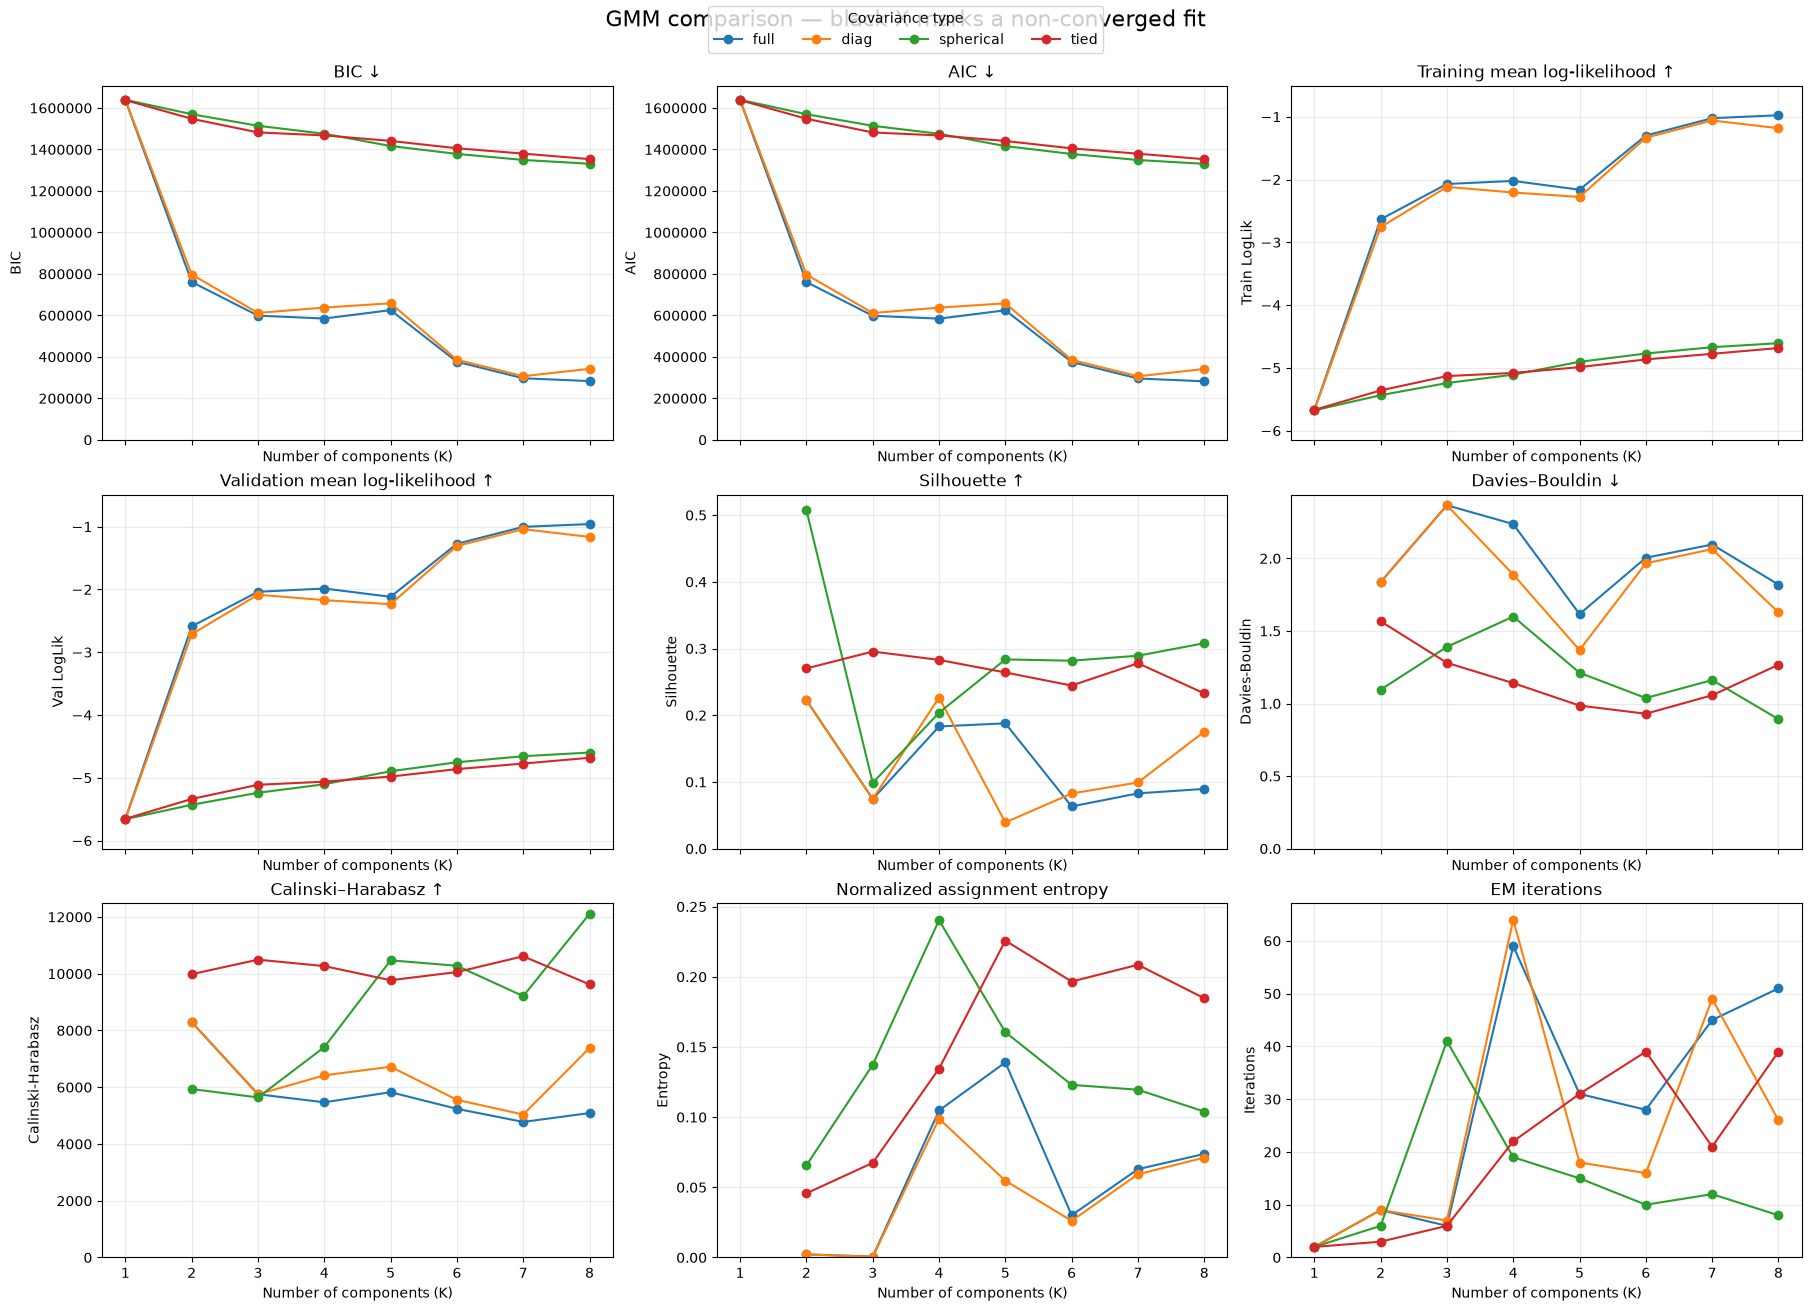

Plot saved to: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/02_gmm_latent_variables_em/gmm_metrics_comparison.png


In [6]:
plot_search(search)

**Observations**
- Full and Diag covariance types are the ones with less balance with complexity and adjustment (AIC and BIC). These two have a better log-likelihood than spherical and tied, showiing a better adjustment in training and validation data.
- Choosing a GMM with \(k=4\) components is a defensible decision in terms of simplicity and interpretability. Although models with more components achieve better probabilistic fit according to AIC and BIC, they also increase model complexity and make the resulting clusters more difficult to interpret. On the other hand, $k=4$ presents a good balance in clustering metrics like Silhouette, Calinski-Harabas, Davies-Bouldin and Davies-Boulding, specially when the covariance_type is diag (excluding spherical and tied because of AIC and BIC).  
- The configuration that will be taken is covariance_type="diag" and $k=4$ because its simplicity in terms of interpretation and balance with adjustment and complexity.

### **3.4 Seed Estabilization**

In [7]:
stability = GMMStability(k=4, covariance_type="diag", n_init_values=(1, 10)).run(data)
display(stability.runs.round(4))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of  20 | elapsed:    2.8s remaining:   25.3s
[Parallel(n_jobs=-1)]: Done   5 out of  20 | elapsed:    5.9s remaining:   17.7s
[Parallel(n_jobs=-1)]: Done   8 out of  20 | elapsed:    6.8s remaining:   10.2s
[Parallel(n_jobs=-1)]: Done  11 out of  20 | elapsed:   38.7s remaining:   31.7s
[Parallel(n_jobs=-1)]: Done  14 out of  20 | elapsed:   44.6s remaining:   19.1s
[Parallel(n_jobs=-1)]: Done  17 out of  20 | elapsed:   50.3s remaining:    8.9s
[Parallel(n_jobs=-1)]: Done  20 out of  20 | elapsed:   52.6s finished



RESULTS BY CONFIGURATION
 n_init  Seed  Converged  Iterations  Train LogLik  Val LogLik         BIC  Predicted Clusters
      1     0       True          12       -1.8918     -1.8630 546812.9080                   4
      1    10       True          12       -1.8918     -1.8630 546812.9080                   4
      1    21       True          64       -2.2064     -2.1704 637690.5390                   4
      1    42       True          64       -2.2064     -2.1704 637684.8422                   4
      1   100       True          25       -2.2982     -2.2573 664206.8069                   4
      1   123       True          25       -2.2982     -2.2573 664208.7354                   4
      1   202       True          25       -2.2982     -2.2573 664206.8752                   4
      1   500       True          25       -2.2982     -2.2573 664208.9078                   4
      1  1000       True          25       -2.2982     -2.2573 664206.8752                   4
      1  2026       True

,n_init,Seed,Converged,Iterations,Train LogLik,Val LogLik,BIC,Predicted Clusters
0,1,0,True,12,-1.8918,-1.8630,546812.9080,4
1,1,10,True,12,-1.8918,-1.8630,546812.9080,4
2,1,21,True,64,-2.2064,-2.1704,637690.5390,4
3,1,42,True,64,-2.2064,-2.1704,637684.8422,4
4,1,100,True,25,-2.2982,-2.2573,664206.8069,4
5,1,123,True,25,-2.2982,-2.2573,664208.7354,4
6,1,202,True,25,-2.2982,-2.2573,664206.8752,4
7,1,500,True,25,-2.2982,-2.2573,664208.9078,4
8,1,1000,True,25,-2.2982,-2.2573,664206.8752,4
9,1,2026,True,12,-1.8918,-1.8630,546812.9073,4


,Mean_ARI,Median_ARI,Min_ARI,Max_ARI,Std_ARI,Mean_Train_LogLik,Std_Train_LogLik,Mean_Val_LogLik,Std_Val_LogLik,Mean_BIC,Mean_Iterations,Convergence_Rate
n_init,,,,,,,,,,,,
1,0.86152,0.87707,0.71308,1.0,0.11392,-2.15791,0.18727,-2.12162,0.18180,623685.23050,28.9,1.0
10,0.94411,1.00000,0.73353,1.0,0.10106,-1.92085,0.10060,-1.89179,0.09808,555215.10803,17.7,1.0


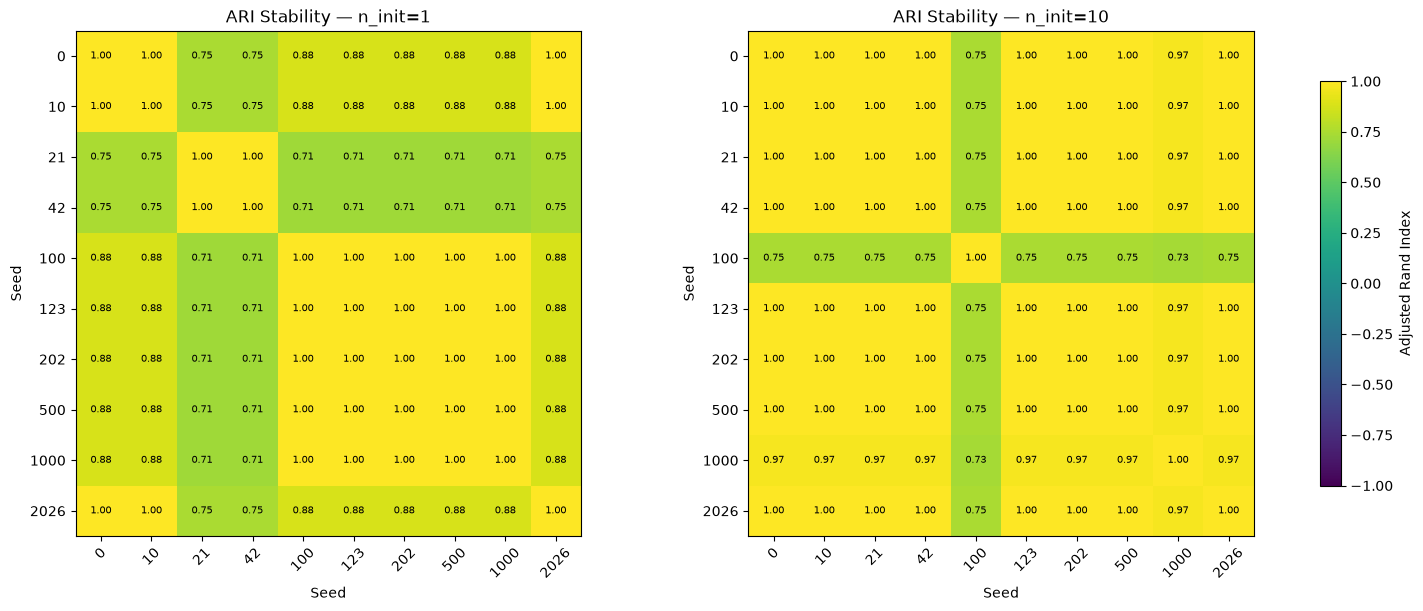

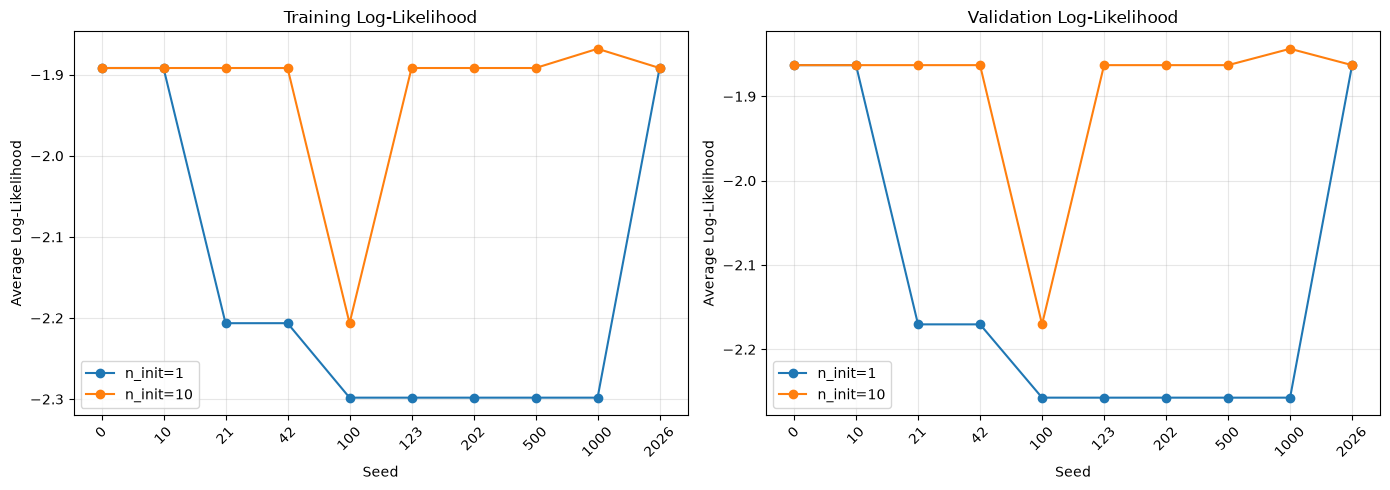

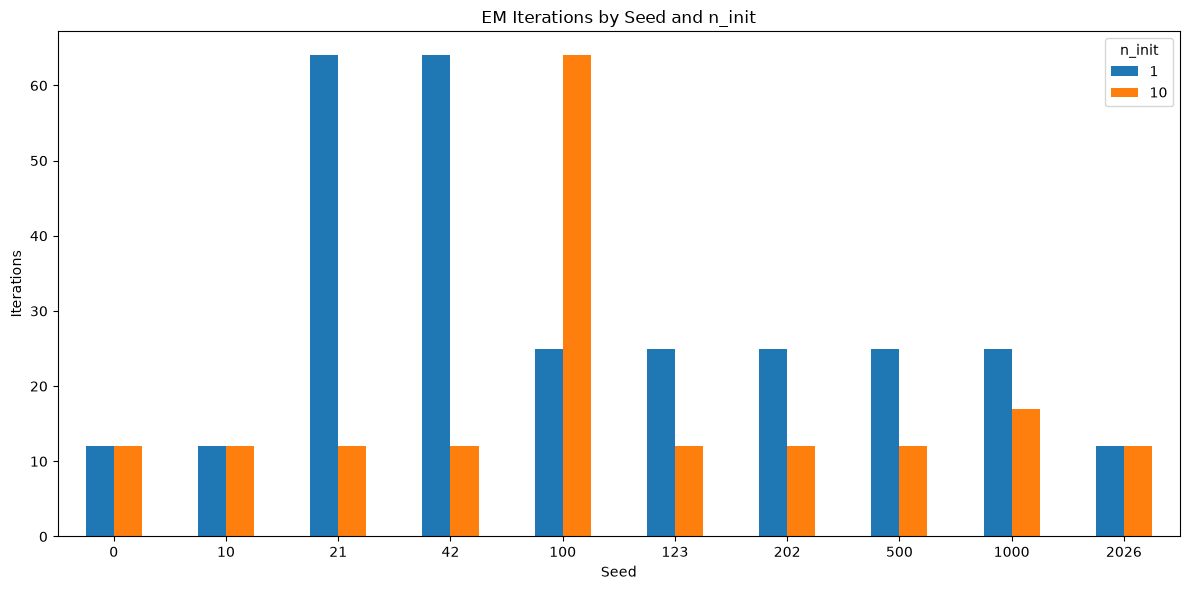

n_init                           10
Seed                           1000
Converged                      True
Iterations                       17
Train LogLik              -1.868044
Val LogLik                -1.843585
BIC                   539962.975954
Predicted Clusters                4
Name: 18, dtype: object

In [8]:
display(stability.summary.round(5))
plot_stability(stability)
stability.runs.loc[stability.runs["Train LogLik"].idxmax()]

**Observations**
- All models converged independently of the seed number.
- There is more stability between seeds when n_init=10 is implemented (ARI = 0.94) in constrast with n_init=1 (0.86)
- In n_init = 10, there was an adjustment decay in the seed 100 where the likelihood decreased more than two units. The partitions of seed 100 were very different in constrast with the other seeds that were taken.
- The use of multiple initializations helps to reduce the risk of congerge to less favorable local optima, but it doesn't guarantee finding the global optimum.

## **4. Clustering Analysis**

### **4.1 GMM**

In [9]:
analysis = GMMAnalysis(data, k=4, covariance_type="diag", n_init=10).fit()

### **4.2 Convergence and EM Iterations**

In [10]:
analysis.convergence_summary()

Converged                True
EM iterations              12
Final lower bound   -1.891766
Training LogLik      -1.89176
Validation LogLik   -1.862991
dtype: object

**Observations**

From the selected configuration $k=4$ and covariance_type="diag", we have:
- The algorithm converged in 12 iterations, which is lower than the maximum number of iterations allowed (300).
- The Log-likelihood in training and validation is very similar which indicates that the probabilistic adjustment is similar in both sets.

### **4.3 Estimation Step**

In [11]:
analysis.responsibilities_summary().round(4)

Number of observations                    36104.0000
Mean max probability                          0.9922
Median max probability                        1.0000
Percentage with max probability < 0.6         0.3158
Percentage with max probability >= 0.9       98.0224
Mean normalized entropy                       0.0183
dtype: float64

**Observations**
- The mean of the probability is high which indicates that the observations in general have a strong probability of belonging to a certain component
- At mininum , 50% of the validation orders have a probability of belonging to a component with a very low or nule uncertainty.
- The 98% of the observations have a strong probability of belonging to a certain component (prob > 0.9).
- There exist a 0.3% of observations that have a max probability below 0.6 of belonging to a certain component.
- The mean normalized entropy is low which indicates that the uncertainty of the orders belonging to a certain component is low. 

### **4.4 Maximization Step**

In [12]:
parameters = analysis.component_parameters()


Mixture weights


,Component,Weight
Component,,
0,0,0.528811
1,1,0.108893
2,2,0.062734
3,3,0.299563


Component means (original units)


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
Component,,,,
0,211.541967,0.101804,0.187688,1.000000
1,110.447744,0.101585,0.191528,2.000000
2,207.597541,0.103024,-1.215645,2.911572
3,222.363415,0.101656,0.255928,4.007027


Component variances (standardized units)


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
Component,,,,
0,1.406585,0.997463,0.406348,0.000010
1,0.087149,1.004292,0.385166,0.000010
2,0.637764,1.002502,2.329946,1.074708
3,0.483477,1.002358,0.153196,0.314704


**Observations**
- Component 0 has de 52% of the weight of the Gaussiang mixtures, followed by components 3 (29%), 1 (10%) and 2 (6%).
- Components 0 and 1 have item quantitys of 1 and 2 respectively, but they have almost 0 variance.
- The item profit ratio mean is negative por component 3 but positive in the other components, despite the variance is high for the feature in this component.
- The average and variance of the componentes in Order Discount Rate Feature are very similar.

### **4.5 Characterization**

#### **4.5.1 Cluster 0**

In [13]:
analysis.analyze_cluster(0)



CLUSTER 0 ANALYSIS
Number of observations: 19,292
Percentage of validation data: 53.43%

DESCRIPTIVE STATISTICS


,mean,std,min,Q1,Median,Q3,max
Sales,213.2738,154.7892,9.99,129.99,199.99,299.98,1999.99
Order Item Discount Rate,0.1014,0.0705,0.00,0.04,0.09,0.16,0.25
Order Item Profit Ratio,0.1903,0.2934,-1.10,0.09,0.28,0.36,0.50
Order Item Quantity,1.0000,0.0000,1.00,1.00,1.00,1.00,1.00



PROFITABILITY ANALYSIS
Negative profit observations: 15.41%


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
80120,199.990005,0.12,0.06,1
120110,299.980011,0.16,0.47,1
40749,399.980011,0.20,0.26,1
81076,199.990005,0.15,-0.23,1
69250,129.990005,0.12,0.13,1
...,...,...,...,...
102838,199.990005,0.10,0.47,1
5638,25.000000,0.04,-0.19,1
60559,299.980011,0.13,0.08,1
101873,199.990005,0.20,0.47,1


**Observations**
- The cluster contains the 53% of all the orders of validation.
- The sales range inside the cluster is high (min 9.9 max 1999.9), the standard deviation is around 154 USD.
- The cluster only contains orders with 1 item.
- The orders usually give profits.

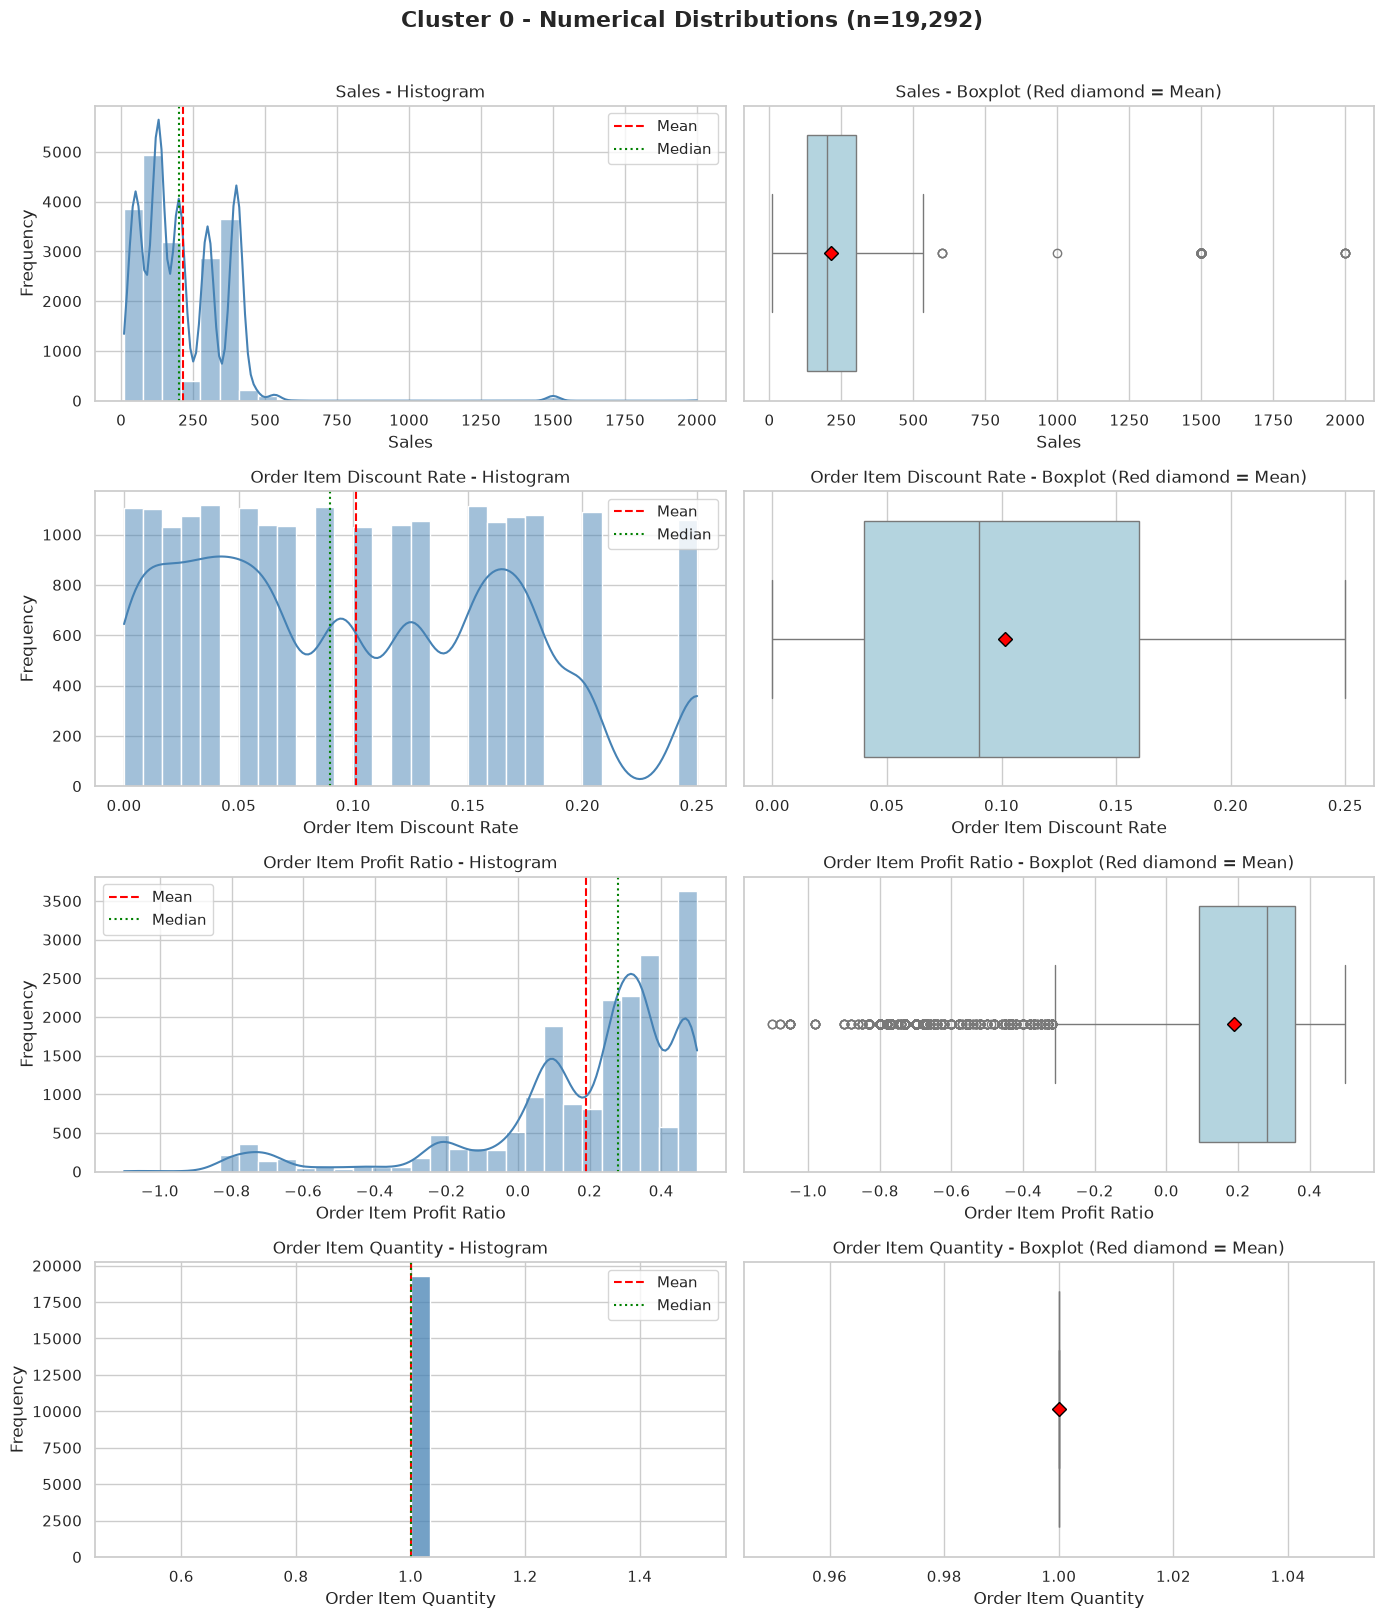

In [14]:
analysis.plot_cluster(0)


In [15]:
analysis.category_counts(0, "Order Country", top=30)


Order Country
Estados Unidos           2555
Francia                  1480
MÃ©xico                  1379
Alemania                 1054
Australia                1008
Reino Unido               852
Brasil                    818
China                     626
India                     570
Italia                    547
Indonesia                 470
EspaÃ±a                   408
Honduras                  385
El Salvador               372
TurquÃ­a                  363
Cuba                      346
RepÃºblica Dominicana     343
Nicaragua                 320
Guatemala                 283
Filipinas                 257
Nigeria                   230
PaÃ­ses Bajos             213
Colombia                  199
Argentina                 192
PanamÃ¡                   168
IrÃ¡n                     152
Nueva Zelanda             150
Austria                   134
Suecia                    119
Marruecos                 117
Name: count, dtype: int64

**Observations**
- The predominant countries are EEUU, France, Mexico, Germany and Australia.

In [16]:
analysis.category_counts(0, "Category Name")


Category Name
Men's Footwear          4251
Fishing                 3477
Water Sports            3036
Camping & Hiking        2689
Cleats                   933
Women's Apparel          831
Indoor/Outdoor Games     731
Cardio Equipment         486
Shop By Sport            443
Children's Clothing      147
Women's Clothing         147
Video Games              146
Electronics              142
Cameras                  118
Toys                     107
Pet Supplies              97
Garden                    97
Consumer Electronics      92
Crafts                    88
Music                     78
Computers                 78
Books                     78
DVDs                      73
Golf Gloves               71
Health and Beauty         70
Accessories               63
CDs                       60
Sporting Goods            59
Golf Balls                57
Trade-In                  52
Men's Clothing            50
Golf Apparel              42
Girls' Apparel            39
Kids' Golf Clubs          38


**Observations**
- The predominant categories are Men's Footwear, Fishing, Water Sports and Camping & Hiking.

#### **4.5.2 Cluster 1**

In [17]:
analysis.analyze_cluster(1)



CLUSTER 1 ANALYSIS
Number of observations: 3,840
Percentage of validation data: 10.64%

DESCRIPTIVE STATISTICS


,mean,std,min,Q1,Median,Q3,max
Sales,110.2355,38.7760,19.98,99.96,100.00,119.98,200.00
Order Item Discount Rate,0.1005,0.0697,0.00,0.04,0.09,0.16,0.25
Order Item Profit Ratio,0.1878,0.2911,-0.88,0.08,0.28,0.36,0.50
Order Item Quantity,2.0000,0.0000,2.00,2.00,2.00,2.00,2.00



PROFITABILITY ANALYSIS
Negative profit observations: 15.94%


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
154389,100.000000,0.00,0.30,2
6382,79.980003,0.10,0.30,2
178319,99.959999,0.25,0.33,2
154312,89.980003,0.00,0.47,2
96671,100.000000,0.13,0.23,2
...,...,...,...,...
95624,199.979996,0.04,0.45,2
124719,199.979996,0.02,0.46,2
22256,119.980003,0.07,0.25,2
8952,119.980003,0.01,-0.21,2


**Observations**
- The cluster contains around de 10% of the validation orders.
- The sales that the company get with these orders are at maximum 200USD.
- The profitability is positive in at minimum the 75% of the data.
- The cluster only contains orders that have 2 items.
- The sales are usually around 100USD.

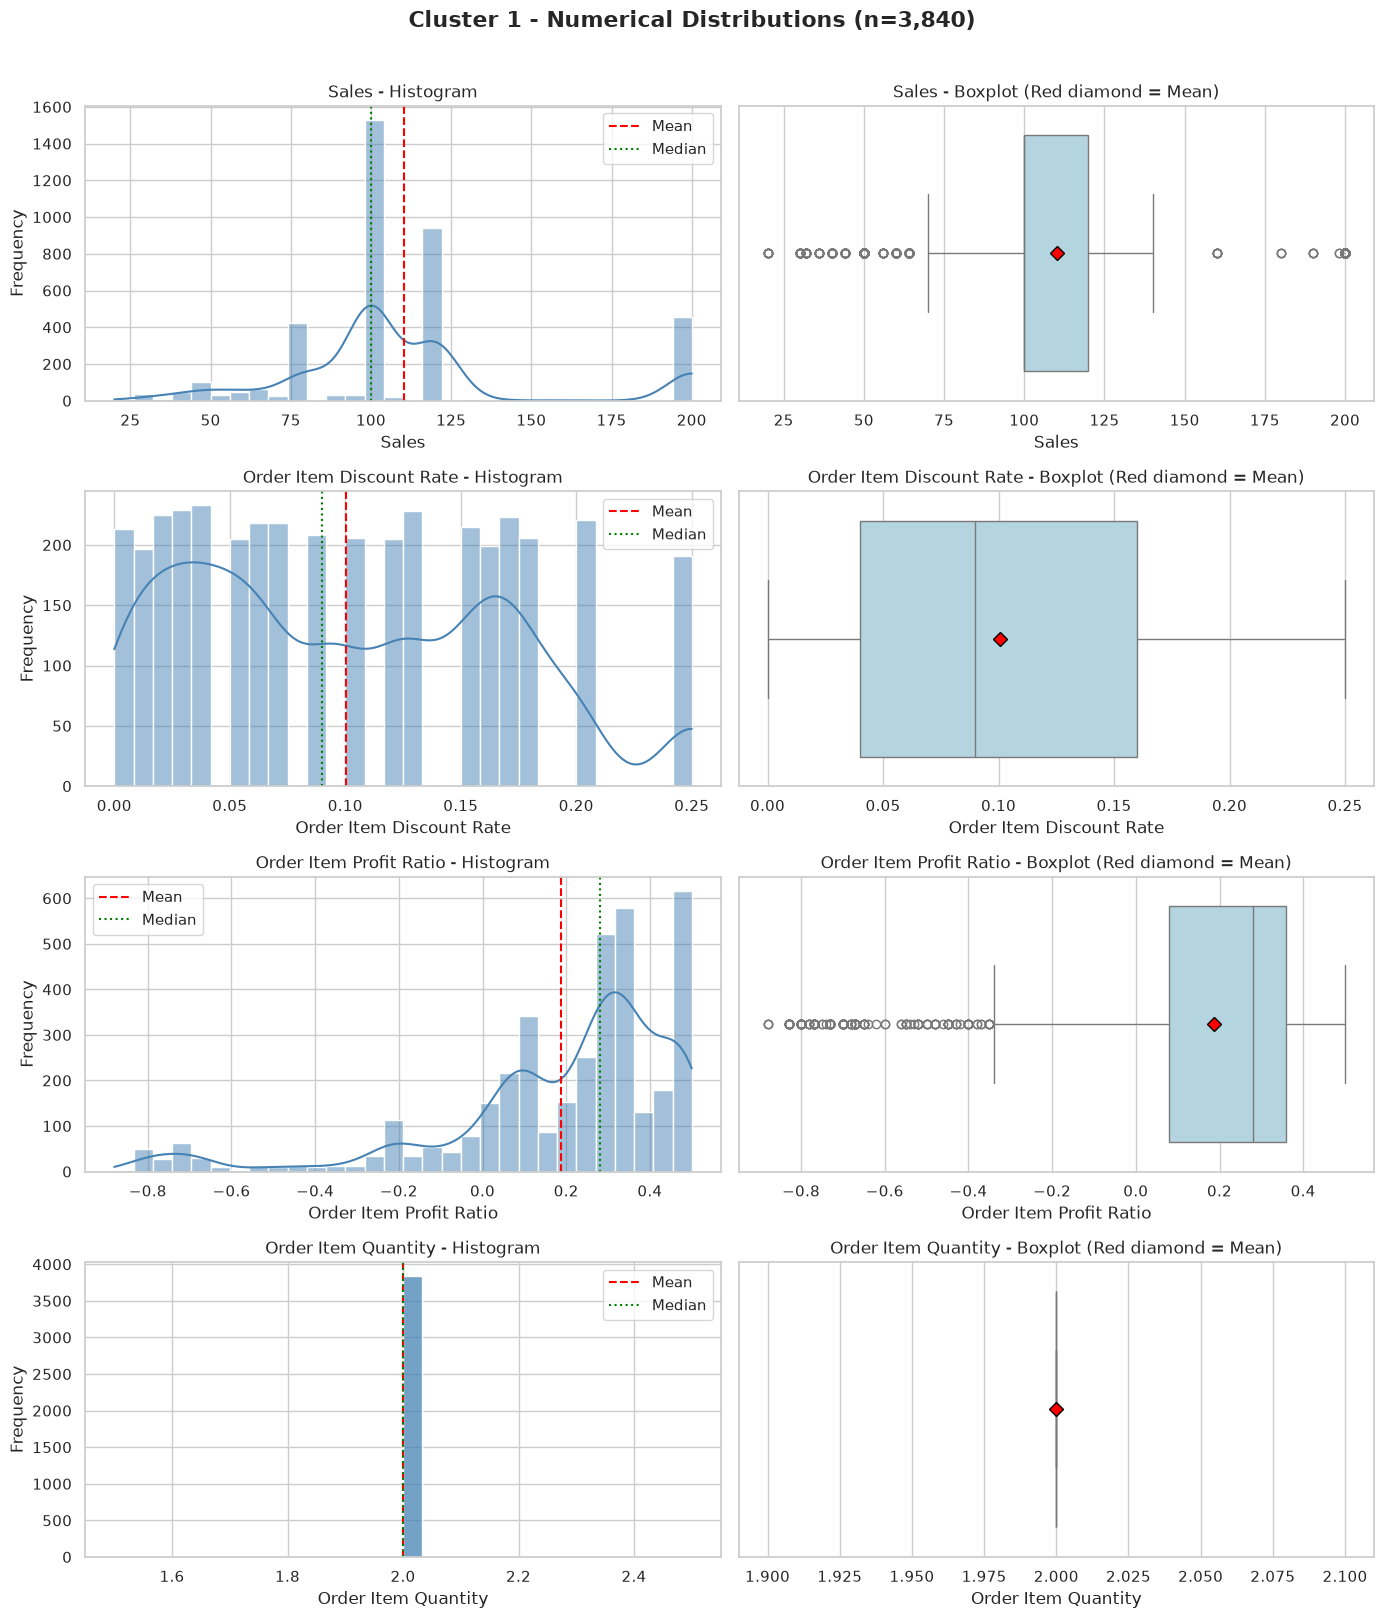

In [18]:
analysis.plot_cluster(1)


In [19]:
analysis.category_counts(1, "Order Country", top=30)


Order Country
Estados Unidos           562
MÃ©xico                  284
Francia                  272
Alemania                 207
Brasil                   191
Reino Unido              141
Australia                136
China                    116
Italia                   107
RepÃºblica Dominicana     97
El Salvador               88
India                     87
EspaÃ±a                   81
Cuba                      75
Indonesia                 72
Honduras                  64
Nicaragua                 64
TurquÃ­a                  62
Guatemala                 60
Nigeria                   58
Filipinas                 50
PanamÃ¡                   43
Colombia                  42
Argentina                 41
PaÃ­ses Bajos             39
Austria                   33
IrÃ¡n                     31
Nueva Zelanda             30
Rusia                     30
SudAfrica                 29
Name: count, dtype: int64

**Observations**
- The predominant countries are EEUU, Mexico, France, Germany and Brasil.

In [20]:
analysis.category_counts(1, "Category Name")


Category Name
Cleats                  929
Women's Apparel         797
Indoor/Outdoor Games    711
Cardio Equipment        454
Shop By Sport           409
Electronics             140
Accessories              67
Golf Balls               47
Girls' Apparel           46
Golf Gloves              33
Trade-In                 31
Hockey                   27
Boxing & MMA             26
Baseball & Softball      23
Tennis & Racquet         19
Golf Shoes               17
Fitness Accessories      15
Golf Apparel             15
Lacrosse                 13
Hunting & Shooting        9
Women's Golf Clubs        4
Men's Golf Clubs          3
As Seen on  TV!           3
Soccer                    1
Kids' Golf Clubs          1
Name: count, dtype: int64

**Observations**
- The predominant categories are Cleats, Women's Apparel, Indoor/Outdoor Games and Shop by Sport.

#### **4.5.3 Cluster 2**

In [21]:
analysis.analyze_cluster(2)



CLUSTER 2 ANALYSIS
Number of observations: 2,100
Percentage of validation data: 5.82%

DESCRIPTIVE STATISTICS


,mean,std,min,Q1,Median,Q3,max
Sales,210.5944,110.0235,11.29,129.99,199.95,299.95,999.99
Order Item Discount Rate,0.1017,0.0684,0.00,0.04,0.10,0.16,0.25
Order Item Profit Ratio,-1.3057,0.6344,-2.75,-1.65,-1.50,-0.73,-0.23
Order Item Quantity,2.8610,1.5368,1.00,1.00,3.00,4.00,5.00



PROFITABILITY ANALYSIS
Negative profit observations: 100.00%


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
107119,199.919998,0.25,-0.67,4
31221,239.960007,0.20,-2.60,4
172533,100.000000,0.10,-2.60,2
27263,129.990005,0.25,-2.70,1
79043,199.990005,0.16,-1.50,1
...,...,...,...,...
154884,150.000000,0.17,-0.80,3
164266,119.970001,0.06,-0.27,3
172044,199.949997,0.01,-0.73,5
30658,129.990005,0.09,-2.70,1


**Observations**
- The cluster represents de 5.8% of the validation data.
- The sales are usually above 100 USD.
- The maximum at sales is 999.99 USD
- The profitability in all the orders inside the cluster is negative.
- The orders inside the cluster go from 1 to 5 items, but there is at least a 50% of the orders that have 3 or more products.

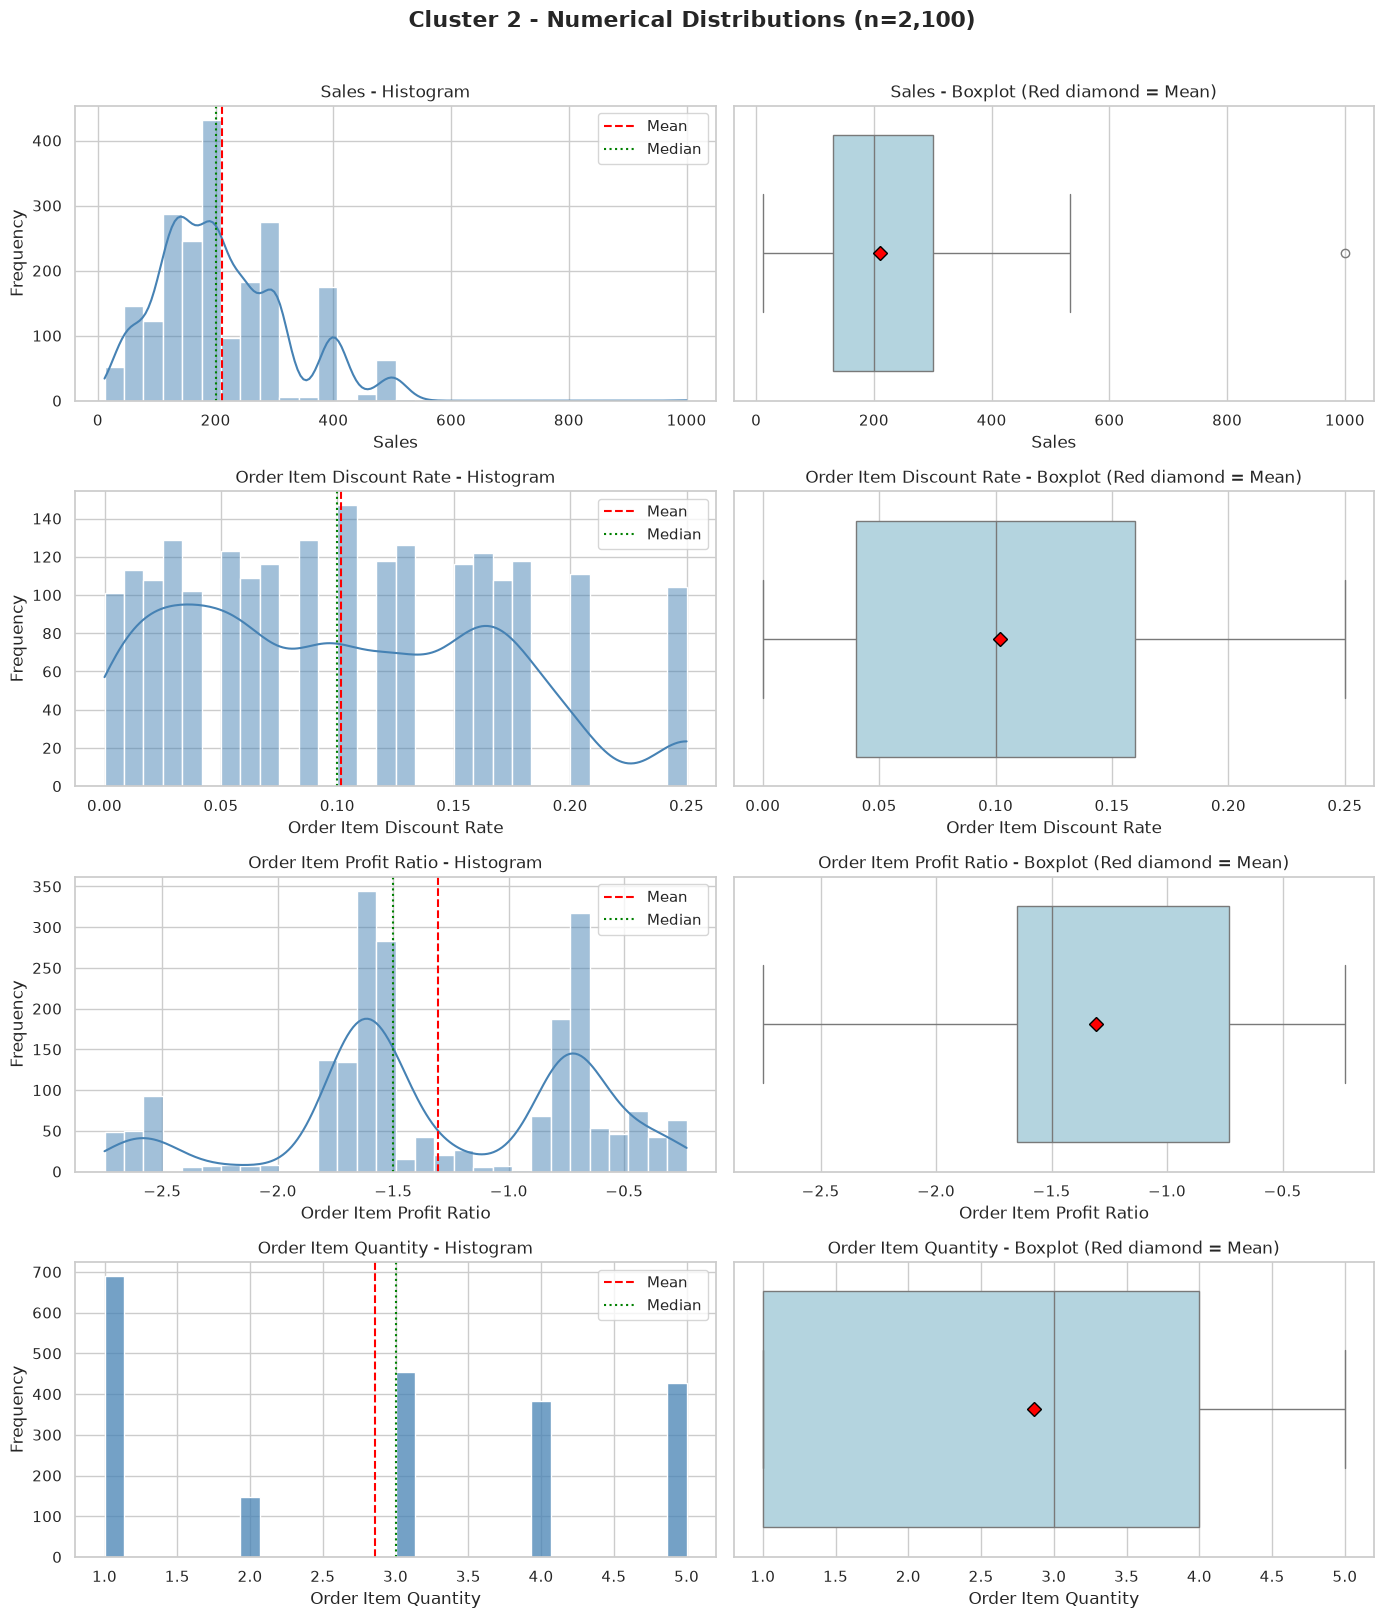

In [22]:
analysis.plot_cluster(2)

In [23]:
analysis.category_counts(2, "Order Country", top=30)

Order Country
Estados Unidos           311
Francia                  156
MÃ©xico                  140
Alemania                 120
Australia                100
Brasil                    99
Reino Unido               77
China                     67
India                     50
Cuba                      49
Italia                    46
TurquÃ­a                  44
El Salvador               42
Guatemala                 41
Honduras                  41
Indonesia                 38
Nicaragua                 38
RepÃºblica Dominicana     38
PanamÃ¡                   30
Nigeria                   29
EspaÃ±a                   29
Filipinas                 25
Argentina                 24
Colombia                  24
PaÃ­ses Bajos             23
Nueva Zelanda             22
IrÃ¡n                     18
Rusia                     16
Egipto                    16
JapÃ³n                    15
Name: count, dtype: int64

**Observations**
- The predominant countries are EEUU, France, Mexico and Germany.

In [24]:
analysis.category_counts(2, "Category Name")


Category Name
Cleats                  356
Women's Apparel         330
Indoor/Outdoor Games    306
Cardio Equipment        201
Shop By Sport           178
Men's Footwear          144
Fishing                 127
Water Sports            105
Camping & Hiking         99
Electronics              39
Accessories              25
Golf Balls               23
Baseball & Softball      16
Girls' Apparel           16
Golf Gloves              15
Hunting & Shooting       10
Golf Apparel              8
Golf Shoes                7
Trade-In                  6
Hockey                    6
Books                     5
Children's Clothing       5
DVDs                      5
Lacrosse                  5
Fitness Accessories       5
Cameras                   5
Consumer Electronics      5
Pet Supplies              4
Boxing & MMA              4
Crafts                    4
Kids' Golf Clubs          4
Video Games               4
Health and Beauty         3
Men's Clothing            3
Toys                      3
Sporti

**Observations**
- The predominant categories are Cleats, Women's Apparel, ndoor/Outdoor Games, Cardio Equipment and Shop By Sport. 

#### **4.5.4 Cluster 3**

In [25]:
analysis.analyze_cluster(3)



CLUSTER 3 ANALYSIS
Number of observations: 10,872
Percentage of validation data: 30.11%

DESCRIPTIVE STATISTICS


,mean,std,min,Q1,Median,Q3,max
Sales,221.8766,92.8525,29.97,150.00,200.00,250.00,500.00
Order Item Discount Rate,0.1007,0.0698,0.00,0.04,0.09,0.16,0.25
Order Item Profit Ratio,0.2506,0.1872,-0.30,0.11,0.29,0.38,0.50
Order Item Quantity,4.0059,0.8169,3.00,3.00,4.00,5.00,5.00



PROFITABILITY ANALYSIS
Negative profit observations: 9.46%


,Sales,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity
19670,250.000000,0.02,0.04,5
114887,249.899994,0.02,0.48,5
56658,119.970001,0.10,-0.20,3
99465,199.919998,0.18,-0.10,4
22688,299.970001,0.09,0.36,3
...,...,...,...,...
35436,299.950012,0.07,0.42,5
130539,239.960007,0.07,0.02,4
22823,179.970001,0.20,0.04,3
57452,119.959999,0.02,0.26,4


**Observations**
- The cluster 3 represents the 30% of the validation orders.
- The 75% of the sales are greater than 150 USD.
- The maximum at sales in the cluster is 500 USD.
- There is a 9.5% of negative profit observations in the cluster.
- The orders of the cluster have 3 or more items.

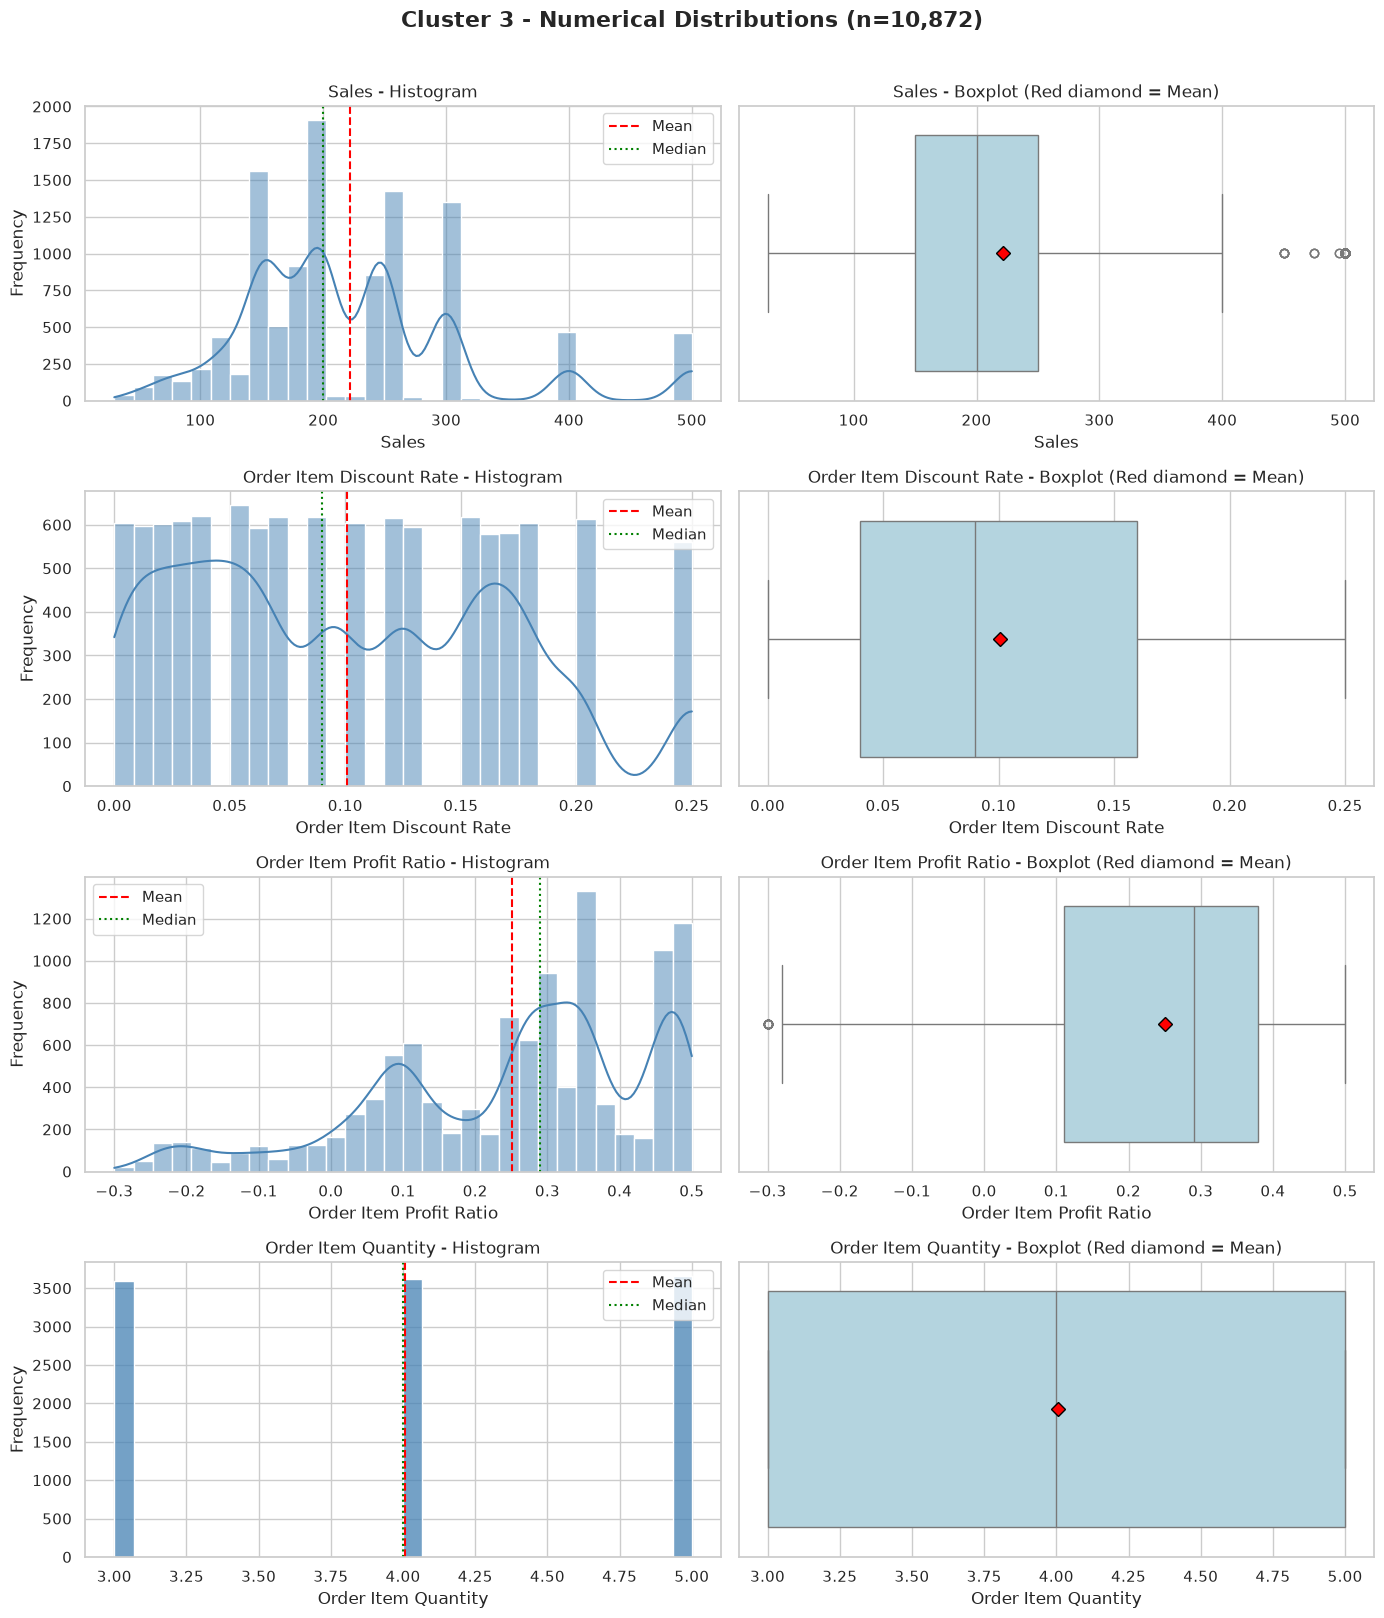

In [26]:
analysis.plot_cluster(3)


In [27]:
analysis.category_counts(3, "Order Country", top=30)


Order Country
Estados Unidos           1632
MÃ©xico                   820
Francia                   776
Alemania                  549
Brasil                    504
Australia                 450
Reino Unido               449
Italia                    322
China                     307
RepÃºblica Dominicana     241
El Salvador               238
India                     236
EspaÃ±a                   235
Honduras                  224
Cuba                      224
TurquÃ­a                  219
Indonesia                 201
Nicaragua                 196
Guatemala                 155
Nigeria                   133
PanamÃ¡                   129
Argentina                 124
Colombia                  113
PaÃ­ses Bajos             113
IrÃ¡n                     105
Austria                   101
Filipinas                  98
Nueva Zelanda              95
Egipto                     88
Rusia                      84
Name: count, dtype: int64

**Observations**
- The predominant countries are EEUU, Mexico, France, Alemania and Brasil.

In [28]:
analysis.category_counts(3, "Category Name")


Category Name
Cleats                  2594
Women's Apparel         2299
Indoor/Outdoor Games    2034
Cardio Equipment        1339
Shop By Sport           1175
Electronics              332
Accessories              212
Golf Balls               156
Girls' Apparel           129
Trade-In                 101
Golf Gloves               93
Baseball & Softball       48
Hockey                    46
Boxing & MMA              44
Golf Shoes                44
Lacrosse                  42
Tennis & Racquet          42
Hunting & Shooting        36
Fitness Accessories       33
Golf Apparel              28
Kids' Golf Clubs          12
Women's Golf Clubs        11
Men's Golf Clubs           8
As Seen on  TV!            8
Soccer                     6
Name: count, dtype: int64

**Observations**
- The predominant categories are Cleats, Women's Apparel, Indoor/Outdoor Games, Cardio Equipment and Shop by Sport.

### **4.6 Identified Order Profiles**

**Profile 0 Mostly profitable single-item orders:** The largest group, representing about 53% of orders. Customers buy one item, usually generating a profit. Sales vary widely, including some expensive purchases.

**Profile 1 Small two-item orders:** About 10% of orders. Customers buy two items, typically spending around $100, with sales up to $200. Most orders are profitable.

**Profile 2 Loss-making orders:** About 5.8% of orders. Every order generates a loss, even though sales are often above $100. Quantities vary from one to five items.

**Profile 3 Mostly profitable orders with several items:** About 30% of orders. Customers buy three or more items, and most orders have sales above $150. Most are profitable, although approximately 9.5% generate losses.